# Notebook 1: Dự Báo Giá Chứng Khoán bằng Vanilla RNN

**ISD-Assignment06 | Dataset 1: Stock Price Prediction (Vanilla RNN)**

---

| Mục | Nội dung |
|-----|----------|
| **Nguồn dữ liệu** | `data/stock_price/all_indices_data.csv` – 36 chỉ số chứng khoán toàn cầu |
| **Mục tiêu** | Dự đoán giá đóng cửa (`close`) ngày tiếp theo |
| **Framework** | PyTorch + Keras (TensorFlow) |
| **Mô hình** | Vanilla RNN (PyTorch `nn.RNN` & Keras `SimpleRNN`) |
| **Metrics** | RMSE · MAE · R² |

### Quy trình Thực Nghiệm
1. **EDA** – Khám phá dữ liệu & tính toán 11 chỉ báo kỹ thuật (OHLCV, Return, MA7, MA21, Volatility, RSI, Bollinger Width).
2. **PyTorch Pipeline** – Huấn luyện mô hình Vanilla RNN (`nn.RNN`) Many-to-One, Gradient Clipping, ReduceLROnPlateau.
3. **Keras Pipeline** – Huấn luyện mô hình SimpleRNN (`layers.SimpleRNN`) 2 tầng + BatchNorm + Dropout, EarlyStopping.
4. **Framework Comparison** – So sánh trực tiếp hiệu năng Vanilla RNN giữa PyTorch và Keras.
5. **Nhận xét & Kết luận** – Đánh giá chuyên sâu về mô hình Vanilla RNN, hiện tượng Vanishing Gradient và khả năng ứng dụng thực tế.


In [6]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Thêm src vào sys.path
SRC_DIR = os.path.join('..', 'src')
sys.path.insert(0, SRC_DIR)

from data_generator import load_real_stock_data, get_available_tickers
import stock_pytorch as pt
import stock_keras as ks

plt.rcParams.update({'figure.figsize': (14, 5), 'font.family': 'DejaVu Sans'})
%matplotlib inline

print('Import thành công các module!')
print(f'   PyTorch device : {pt.DEVICE}')

Import thành công các module!
   PyTorch device : cpu


---
## Phần 1: Khám Phá Dữ Liệu (EDA)

In [7]:
# ── Danh sách tickers khả dụng (>= 500 phiên) ──
tickers = get_available_tickers(min_rows=500)
print(f'Tổng số ticker khả dụng: {len(tickers)}')
for i, t in enumerate(tickers, 1):
    print(f'   {i:2d}. {t}')

Tổng số ticker khả dụng: 35
    1. 000001.SS
    2. 399001.SZ
    3. IMOEX.ME
    4. ^AORD
    5. ^AXJO
    6. ^BFX
    7. ^BSESN
    8. ^BUK100P
    9. ^BVSP
   10. ^DJI
   11. ^FCHI
   12. ^FTSE
   13. ^GDAXI
   14. ^GSPC
   15. ^GSPTSE
   16. ^HSI
   17. ^IPSA
   18. ^IXIC
   19. ^JKSE
   20. ^JN0U.JO
   21. ^KLSE
   22. ^KS11
   23. ^MERV
   24. ^MXX
   25. ^N100
   26. ^N225
   27. ^NYA
   28. ^NZ50
   29. ^RUT
   30. ^STI
   31. ^STOXX50E
   32. ^TA125.TA
   33. ^TWII
   34. ^VIX
   35. ^XAX


In [8]:
# ── Cấu hình bài toán ──
TICKER = '^GSPC'   # S&P 500 Index
WINDOW = 20        # Cửa sổ trượt 20 phiên giao dịch

# ── Load & Tiền xử lý dữ liệu ──
data = load_real_stock_data(ticker=TICKER, window_size=WINDOW, train_ratio=0.8)
df   = data['df_full']

print(f'\nThông tin chỉ số [{TICKER}] – S&P 500:')
print(f'   Tổng phiên giao dịch : {len(df):,}')
print(f'   Khoảng thời gian     : {df["date"].min().date()} → {df["date"].max().date()}')
print(f'   Train samples (X)    : {data["X_train"].shape}')
print(f'   Test samples (X)     : {data["X_test"].shape}')
print(f'   Features ({len(data["feature_names"])} đặc trưng) : {data["feature_names"]}')
print()
df[['open','high','low','close','volume','return','rsi_14']].describe().round(3)

[Stock] Ticker: ^GSPC | Tổng: 24,215 phiên | Train: 19,352 | Test: 4,823 | Features: 11 | Window: 20

Thông tin chỉ số [^GSPC] – S&P 500:
   Tổng phiên giao dịch : 24,215
   Khoảng thời gian     : 1928-01-30 → 2024-06-24
   Train samples (X)    : (19352, 20, 11)
   Test samples (X)     : (4823, 20, 11)
   Features (11 đặc trưng) : ['open', 'high', 'low', 'close', 'volume', 'return', 'ma7', 'ma21', 'volatility_7d', 'rsi_14', 'bb_width']



,open,high,low,close,volume,return,rsi_14
count,24215.000,24215.000,24215.000,24215.000,2.421500e+04,24215.000,24215.000
mean,611.357,634.900,627.288,631.342,9.038974e+08,0.000,54.174
std,1032.962,1027.508,1015.924,1022.114,1.616540e+09,0.012,17.904
min,0.000,4.400,4.400,4.400,0.000000e+00,-0.205,2.320
25%,9.670,24.700,24.700,24.700,1.530000e+06,-0.005,41.308
50%,42.590,103.030,101.380,102.200,2.027000e+07,0.000,54.474
75%,1023.675,1031.860,1015.270,1023.675,9.628500e+08,0.005,67.266
max,5499.990,5505.530,5471.320,5487.030,1.145623e+10,0.166,100.000


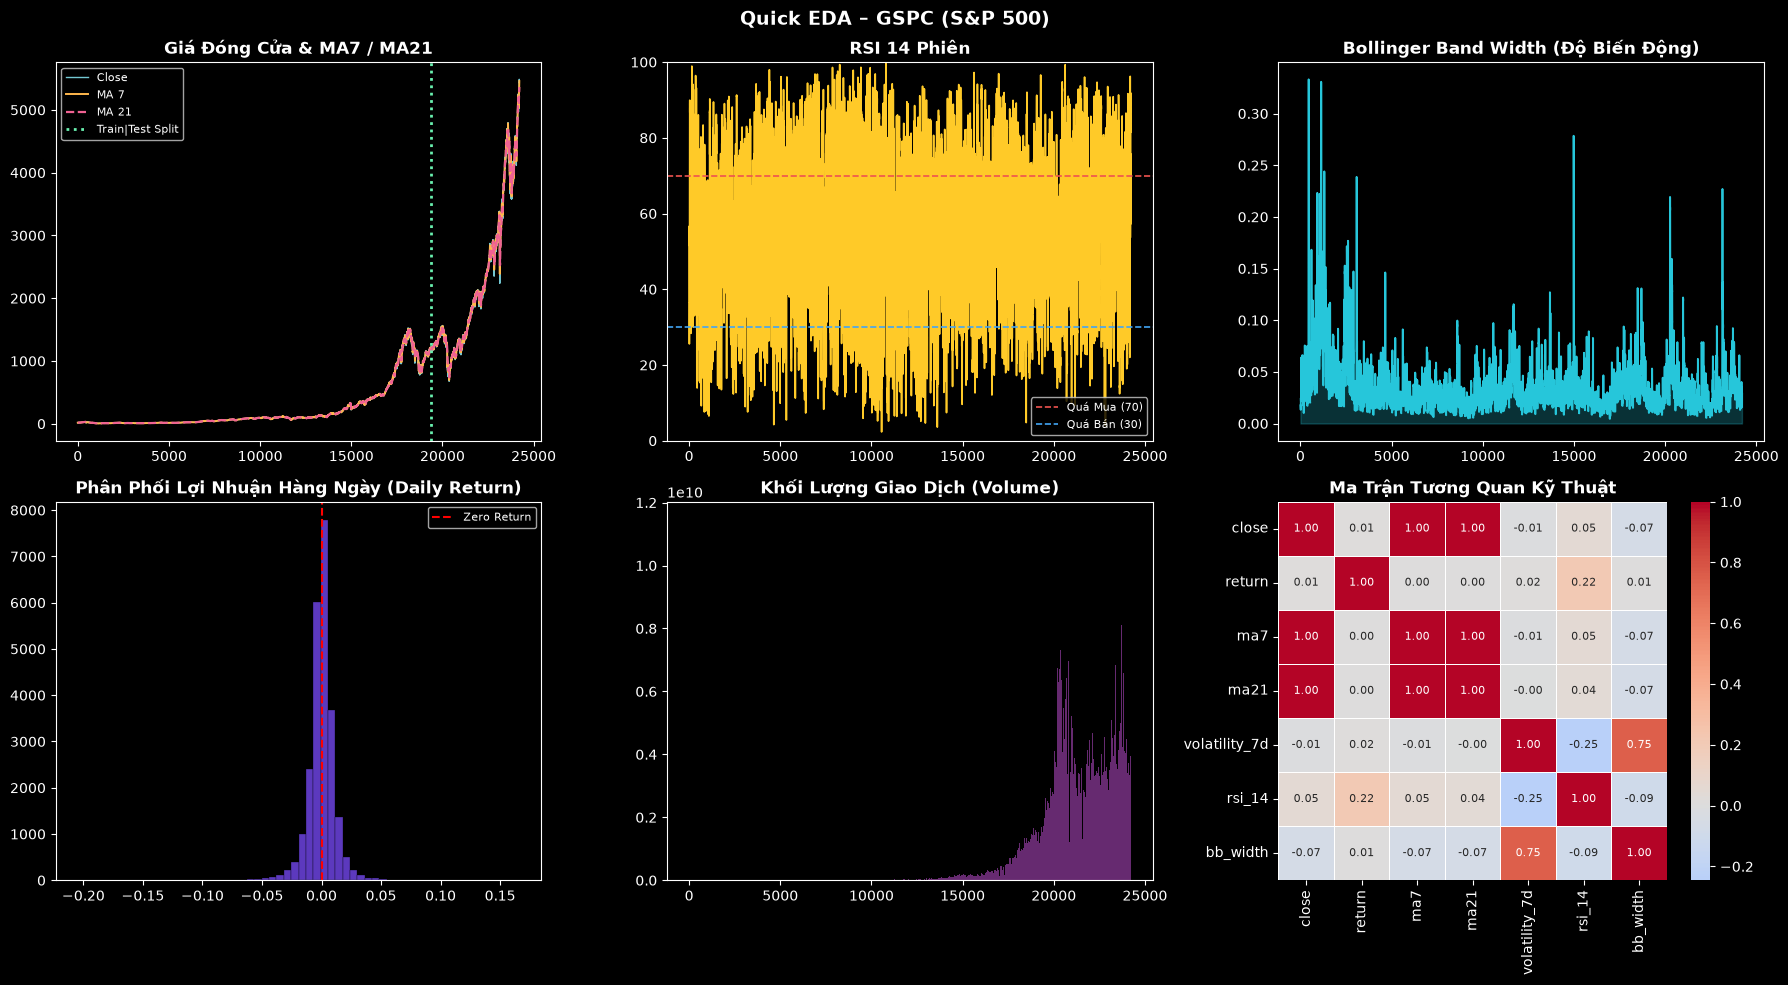

Biểu đồ EDA chi tiết được tự động lưu trong reports/figures/.


In [9]:
# ── Trực quan hóa EDA Tổng quan ──
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle(f'Quick EDA – {TICKER.replace("^","")} (S&P 500)', fontsize=14, fontweight='bold')

# 1. Giá đóng cửa & Moving Averages
ax = axes[0, 0]
ax.plot(df.index, df['close'], '#80DEEA', lw=1.0, alpha=0.9, label='Close')
ax.plot(df.index, df['ma7'],   '#FFB74D', lw=1.4, label='MA 7')
ax.plot(df.index, df['ma21'],  '#F06292', lw=1.6, ls='--', label='MA 21')
ax.axvline(data['train_size'], color='#69F0AE', lw=2, ls=':', label='Train|Test Split')
ax.set_title('Giá Đóng Cửa & MA7 / MA21', fontweight='bold'); ax.legend(fontsize=8)

# 2. RSI 14
ax = axes[0, 1]
ax.plot(df.index, df['rsi_14'], '#FFCA28', lw=1.2)
ax.axhline(70, color='#EF5350', ls='--', lw=1.2, label='Quá Mua (70)')
ax.axhline(30, color='#42A5F5', ls='--', lw=1.2, label='Quá Bán (30)')
ax.set_ylim(0, 100); ax.set_title('RSI 14 Phiên', fontweight='bold'); ax.legend(fontsize=8)

# 3. Bollinger Band Width
ax = axes[0, 2]
ax.plot(df.index, df['bb_width'], '#26C6DA', lw=1.3)
ax.fill_between(df.index, 0, df['bb_width'], alpha=0.25, color='#26C6DA')
ax.set_title('Bollinger Band Width (Độ Biến Động)', fontweight='bold')

# 4. Daily Return distribution
ax = axes[1, 0]
ax.hist(df['return'].dropna(), bins=60, color='#7C4DFF', alpha=0.75, edgecolor='black', lw=0.3)
ax.axvline(0, color='red', ls='--', lw=1.5, label='Zero Return')
ax.set_title('Phân Phối Lợi Nhuận Hàng Ngày (Daily Return)', fontweight='bold'); ax.legend(fontsize=8)

# 5. Volume
ax = axes[1, 1]
ax.bar(df.index, df['volume'], color='#AB47BC', alpha=0.6, width=1.0)
ax.set_title('Khối Lượng Giao Dịch (Volume)', fontweight='bold')

# 6. Correlation heatmap
ax = axes[1, 2]
cols = ['close', 'return', 'ma7', 'ma21', 'volatility_7d', 'rsi_14', 'bb_width']
sns.heatmap(df[cols].corr(), annot=True, fmt='.2f', cmap='coolwarm',
            ax=ax, center=0, linewidths=0.5, annot_kws={'size': 8})
ax.set_title('Ma Trận Tương Quan Kỹ Thuật', fontweight='bold')

plt.tight_layout(); plt.show()
print('Biểu đồ EDA chi tiết được tự động lưu trong reports/figures/.')

---
## Phần 2: PyTorch Pipeline – Vanilla RNN

**Kiến trúc `StockRNNModel` (Vanilla RNN):**
```text
[Input (B, 20, 11)] → [Vanilla RNN (nn.RNN) × 2 layers, hidden=128] → Dropout(0.25)
                     → [Linear(128 → 64) → ReLU → Dropout(0.25)]
                     → [Linear(64 → 32) → ReLU]
                     → [Linear(32 → 1)]  # Dự đoán close price
```
**Kỹ thuật tối ưu:** Gradient Clipping (`max_norm=1.0`) · ReduceLROnPlateau · Time-based Split (không shuffle).

In [10]:
# ── Huấn luyện Vanilla RNN bằng PyTorch ──
pytorch_results = pt.run_pipeline(
    ticker      = TICKER,
    window_size = WINDOW,
    epochs      = 60,
    batch_size  = 64,
    hidden_dim  = 128,
    train_ratio = 0.8,
)


  PYTORCH STOCK PIPELINE (RNN) – GSPC
[Stock] Ticker: ^GSPC | Tổng: 24,215 phiên | Train: 19,352 | Test: 4,823 | Features: 11 | Window: 20

[EDA] Đang vẽ biểu đồ phân tích...
[OK] EDA → G:\Workplace\ISD-Assignment06\notebooks\..\src\..\reports\figures\eda_GSPC_pytorch.png

  [Train] RNN (Vanilla RNN)...
  [010/60] Train: 0.024796 | Val: 1.289866
  [020/60] Train: 0.074175 | Val: 2.519120
  [030/60] Train: 0.045257 | Val: 2.183926
  [040/60] Train: 0.003994 | Val: 1.530159
  [050/60] Train: 0.002381 | Val: 1.530701
  [060/60] Train: 0.001492 | Val: 1.476983
  → RMSE: 1430.2414 | MAE: 995.4224 | R²: -0.5018
[OK] RNN → G:\Workplace\ISD-Assignment06\notebooks\..\src\..\reports\figures\stock_GSPC_rnn_pytorch.png

───────────────────────────────────────────────────────
  KẾT QUẢ PYTORCH (RNN) – Chứng Khoán [GSPC]
───────────────────────────────────────────────────────
  Model          RMSE        MAE         R²
  ──────────────────────────────────────────
  RNN       1430.2414   995.4224   

Biểu đồ EDA – Chứng khoán (PyTorch):


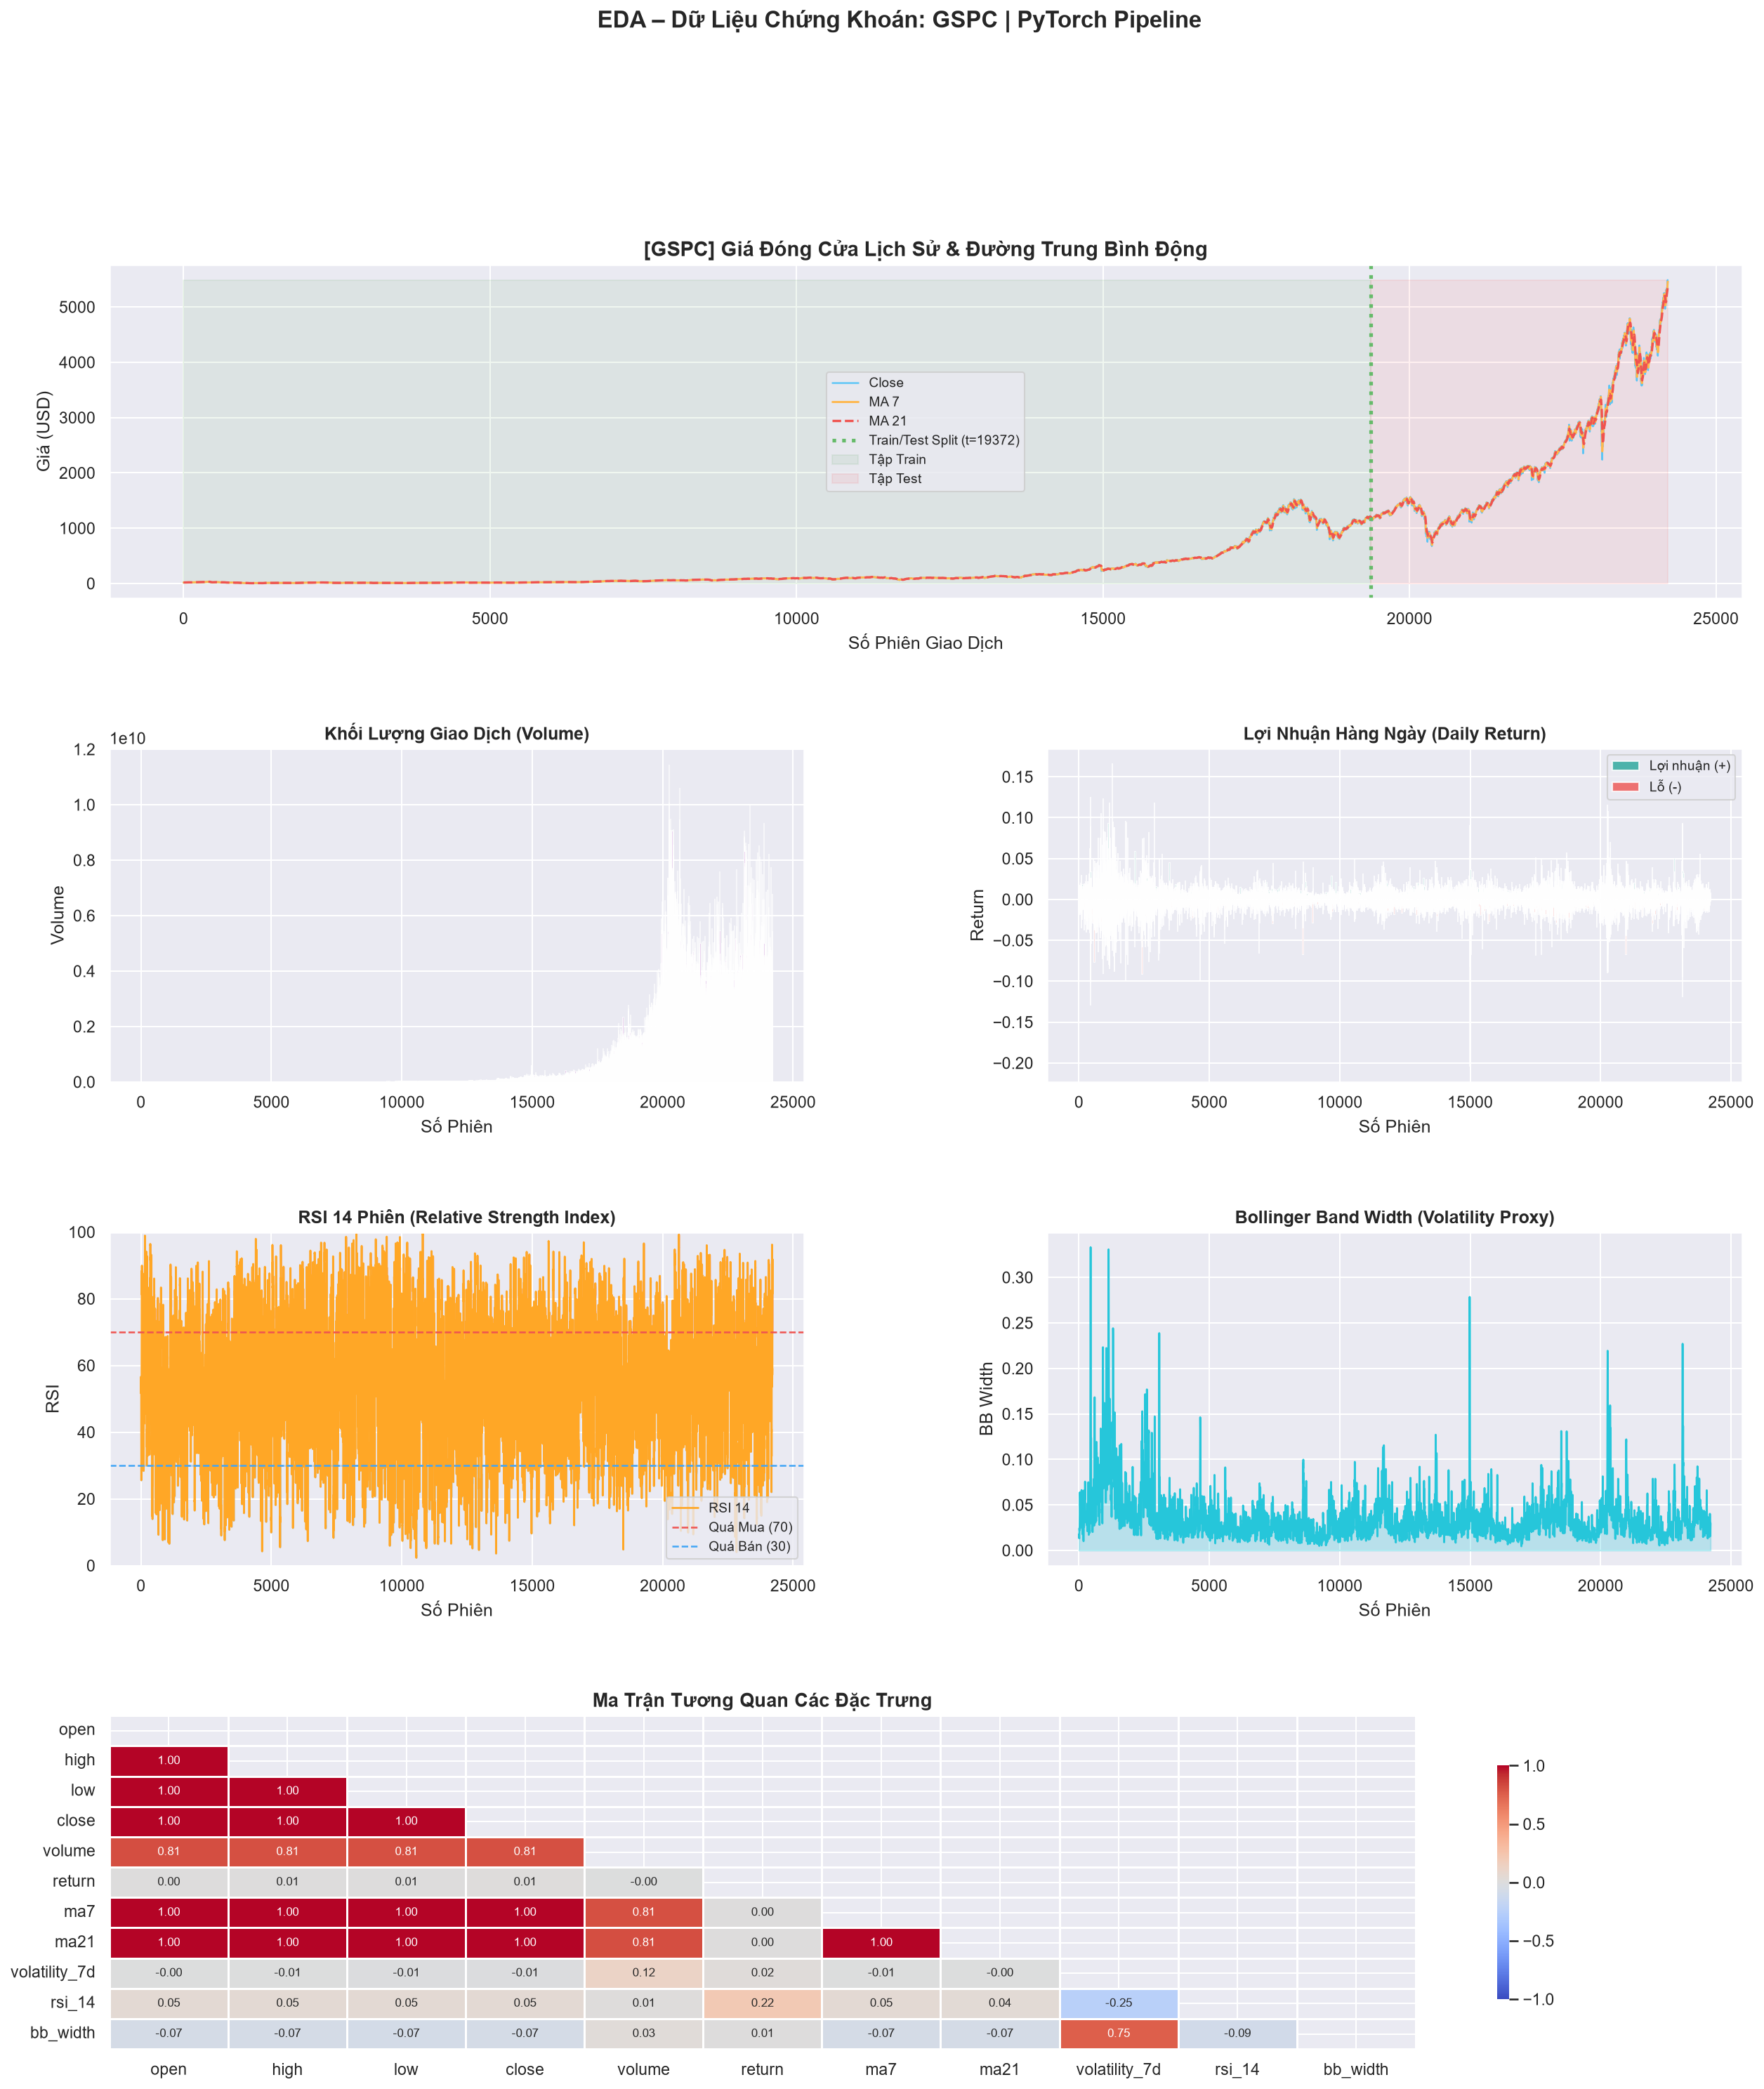

Kết Quả Huấn Luyện PyTorch Vanilla RNN:


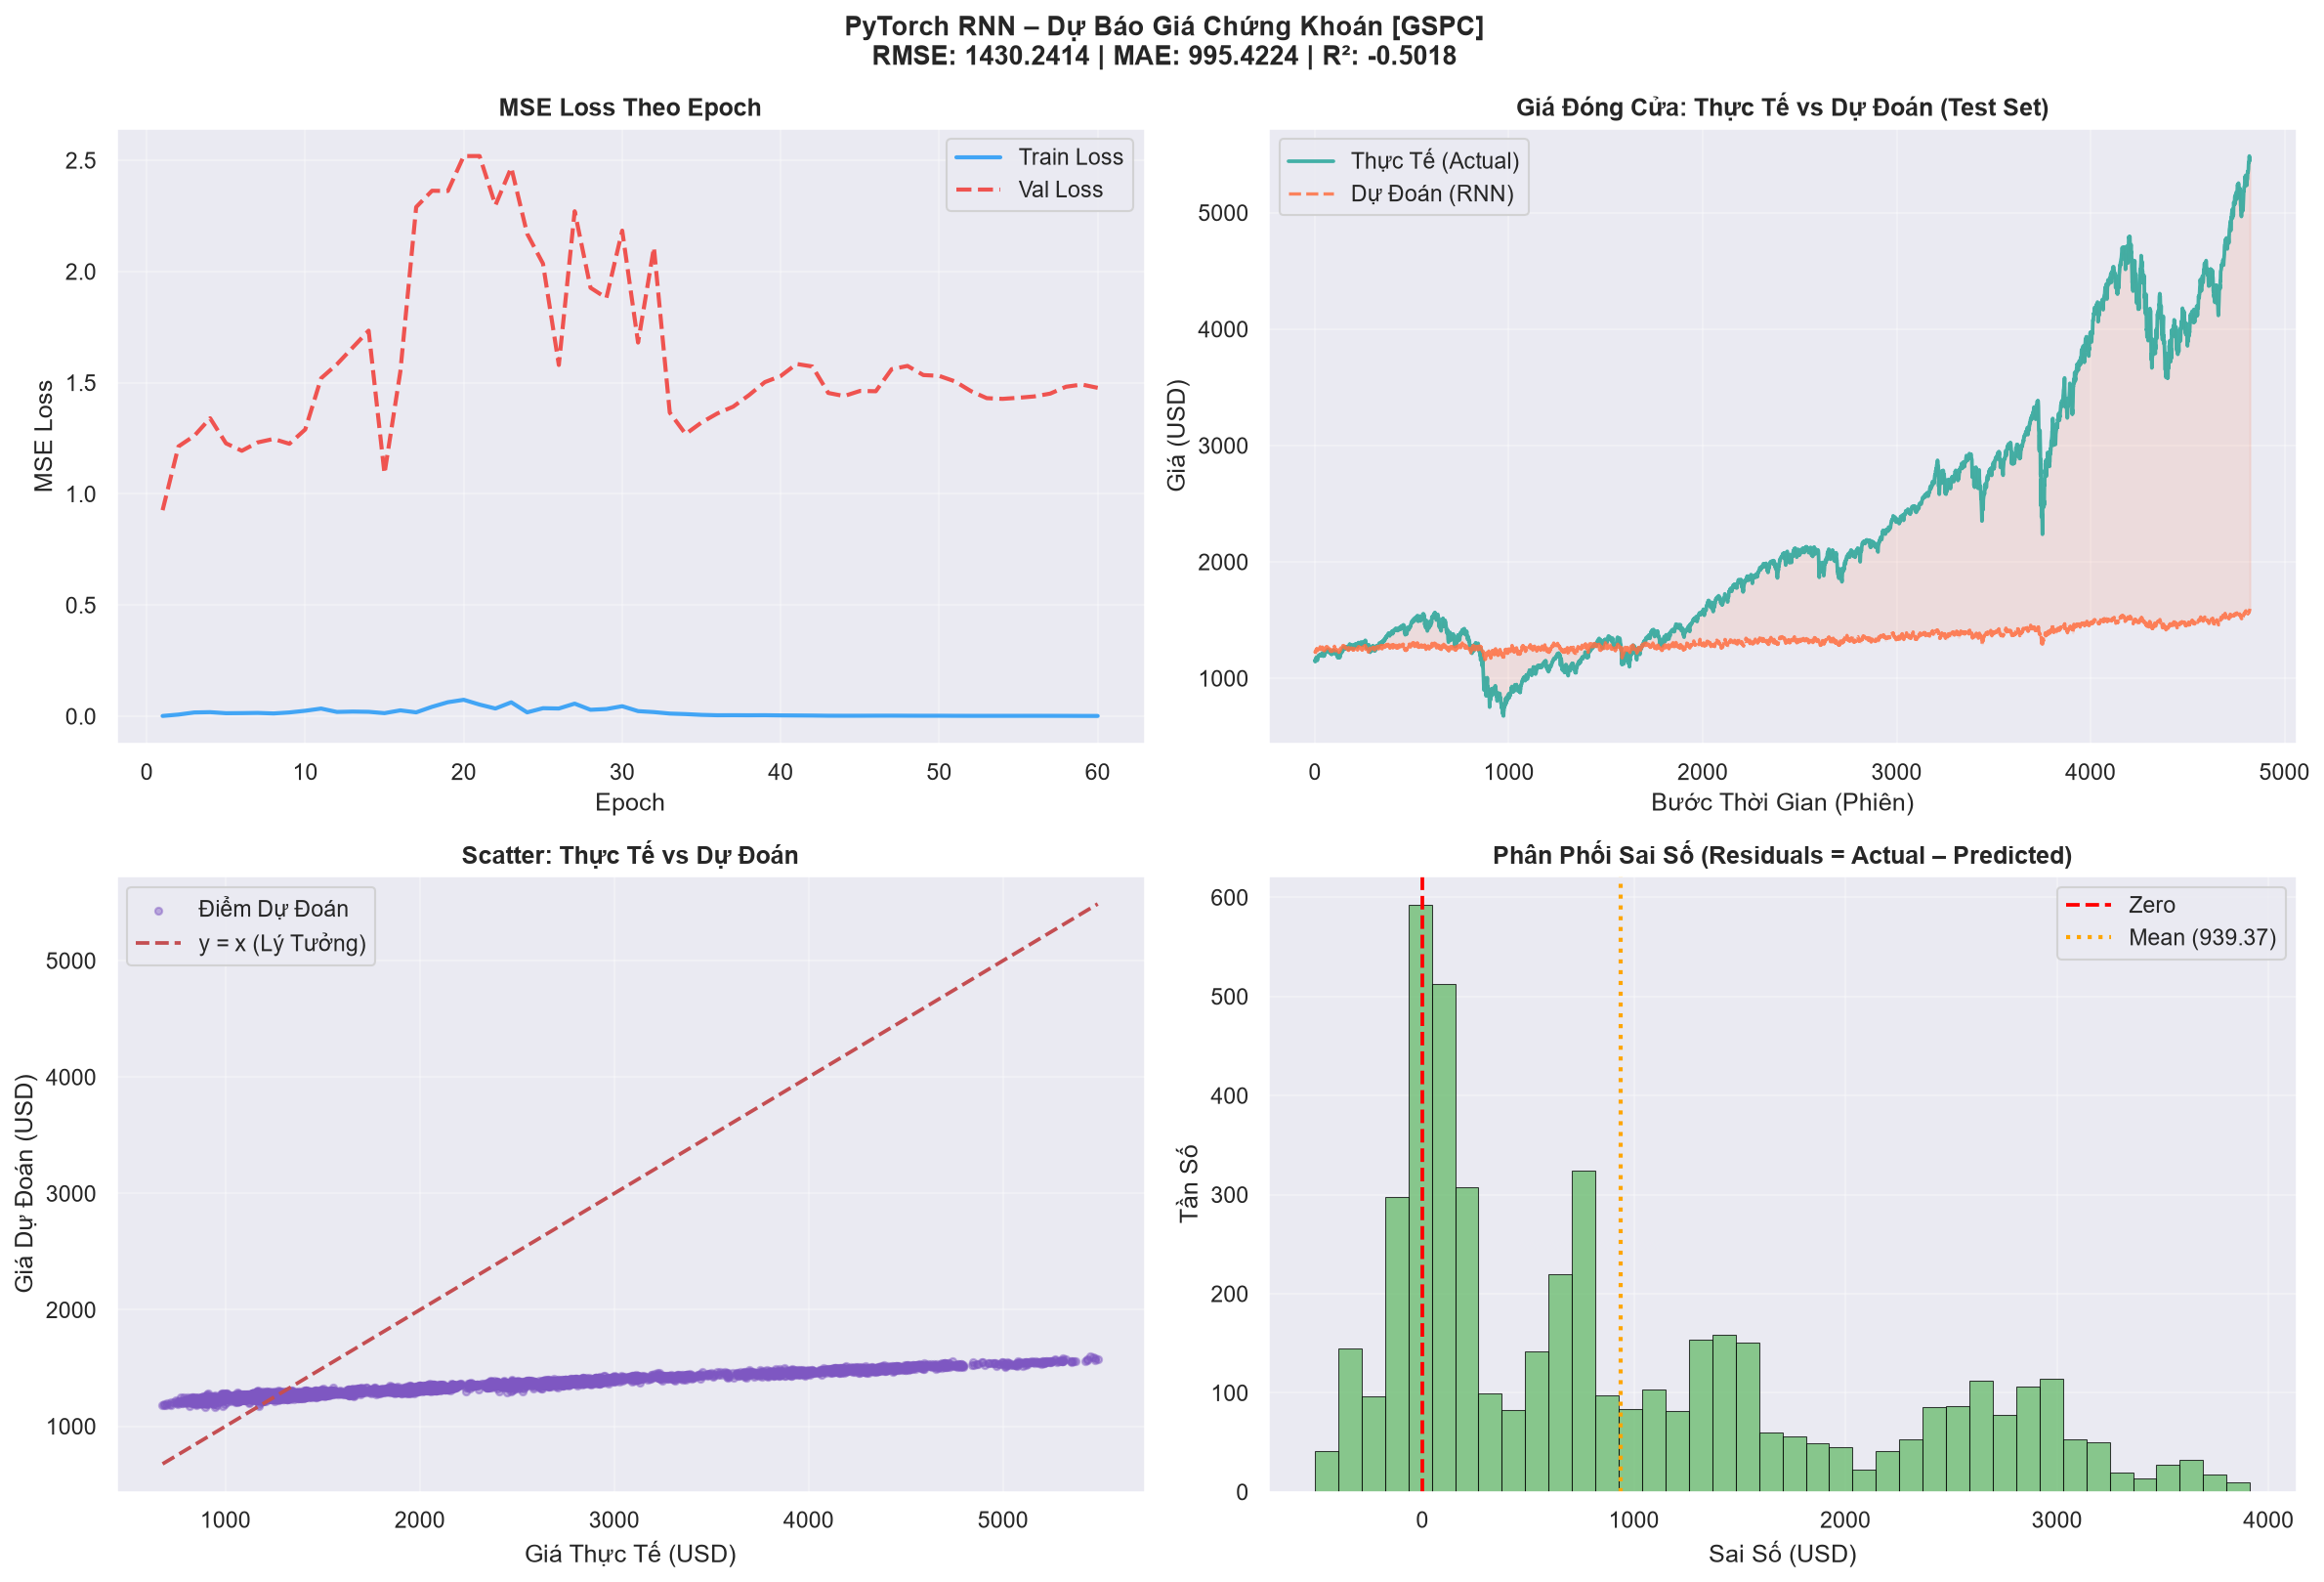

In [11]:
# ── Hiển thị biểu đồ EDA & Kết quả PyTorch Vanilla RNN ──
from IPython.display import Image, display
FIG_DIR = os.path.join('..', 'reports', 'figures')
TL = TICKER.replace('^', '')

# 1. EDA Figure
eda_path = os.path.join(FIG_DIR, f'eda_{TL}_pytorch.png')
if os.path.exists(eda_path):
    print('Biểu đồ EDA – Chứng khoán (PyTorch):')
    display(Image(filename=eda_path, width=950))

# 2. PyTorch RNN Figure
rnn_path = os.path.join(FIG_DIR, f'stock_{TL}_rnn_pytorch.png')
if os.path.exists(rnn_path):
    print('Kết Quả Huấn Luyện PyTorch Vanilla RNN:')
    display(Image(filename=rnn_path, width=950))

---
## Phần 3: Keras Pipeline – SimpleRNN

**Kiến trúc `build_model` (Vanilla SimpleRNN):**
```text
[SimpleRNN(128 units, return_sequences=True)] → Dropout(0.25) → BatchNorm
[SimpleRNN(64 units,  return_sequences=False)] → Dropout(0.25) → BatchNorm
Dense(64, activation='relu') → Dropout(0.125) → Dense(32, activation='relu') → Dense(1)
```
**Callbacks:** `EarlyStopping(patience=12, restore_best_weights=True)` · `ReduceLROnPlateau(factor=0.5, patience=6)`

In [12]:
# ── Huấn luyện SimpleRNN bằng Keras / TensorFlow ──
keras_results = ks.run_pipeline(
    ticker          = TICKER,
    window_size     = WINDOW,
    epochs          = 80,
    batch_size      = 64,
    units           = 128,
    train_ratio     = 0.8,
    pytorch_results = pytorch_results,   # So sánh trực tiếp với PyTorch
)


  KERAS STOCK PIPELINE (RNN) – GSPC
[Stock] Ticker: ^GSPC | Tổng: 24,215 phiên | Train: 19,352 | Test: 4,823 | Features: 11 | Window: 20

[EDA] Đang vẽ biểu đồ phân tích...
[OK] EDA → G:\Workplace\ISD-Assignment06\notebooks\..\src\..\reports\figures\eda_GSPC_keras.png

  [Train] Keras RNN (SimpleRNN)...


Model: "RNN_stock"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ RNN_1 (SimpleRNN)                    │ (None, 20, 128)             │          17,920 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 20, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 20, 128)             │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ RNN_2 (SimpleRNN)                    │ (None, 64)                  │          12,352 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 64)                  │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output (Dense)                       │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 37,313 (145.75 KB)

 Trainable params: 36,929 (144.25 KB)

 Non-trainable params: 384 (1.50 KB)


Epoch 10: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 16: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
Epoch 16: early stopping
Restoring model weights from the end of the best epoch: 4.
  → RMSE: 1516.8771 | MAE: 1097.9727 | R²: -0.6892
[OK] RNN → G:\Workplace\ISD-Assignment06\notebooks\..\src\..\reports\figures\stock_GSPC_rnn_keras.png
[OK] Framework comparison → G:\Workplace\ISD-Assignment06\notebooks\..\src\..\reports\figures\stock_framework_GSPC.png

───────────────────────────────────────────────────────
  KẾT QUẢ KERAS (RNN) – Chứng Khoán [GSPC]
───────────────────────────────────────────────────────
  Model          RMSE        MAE         R²
  ──────────────────────────────────────────
  RNN       1516.8771  1097.9727    -0.6892


EDA – Chứng khoán (Keras):


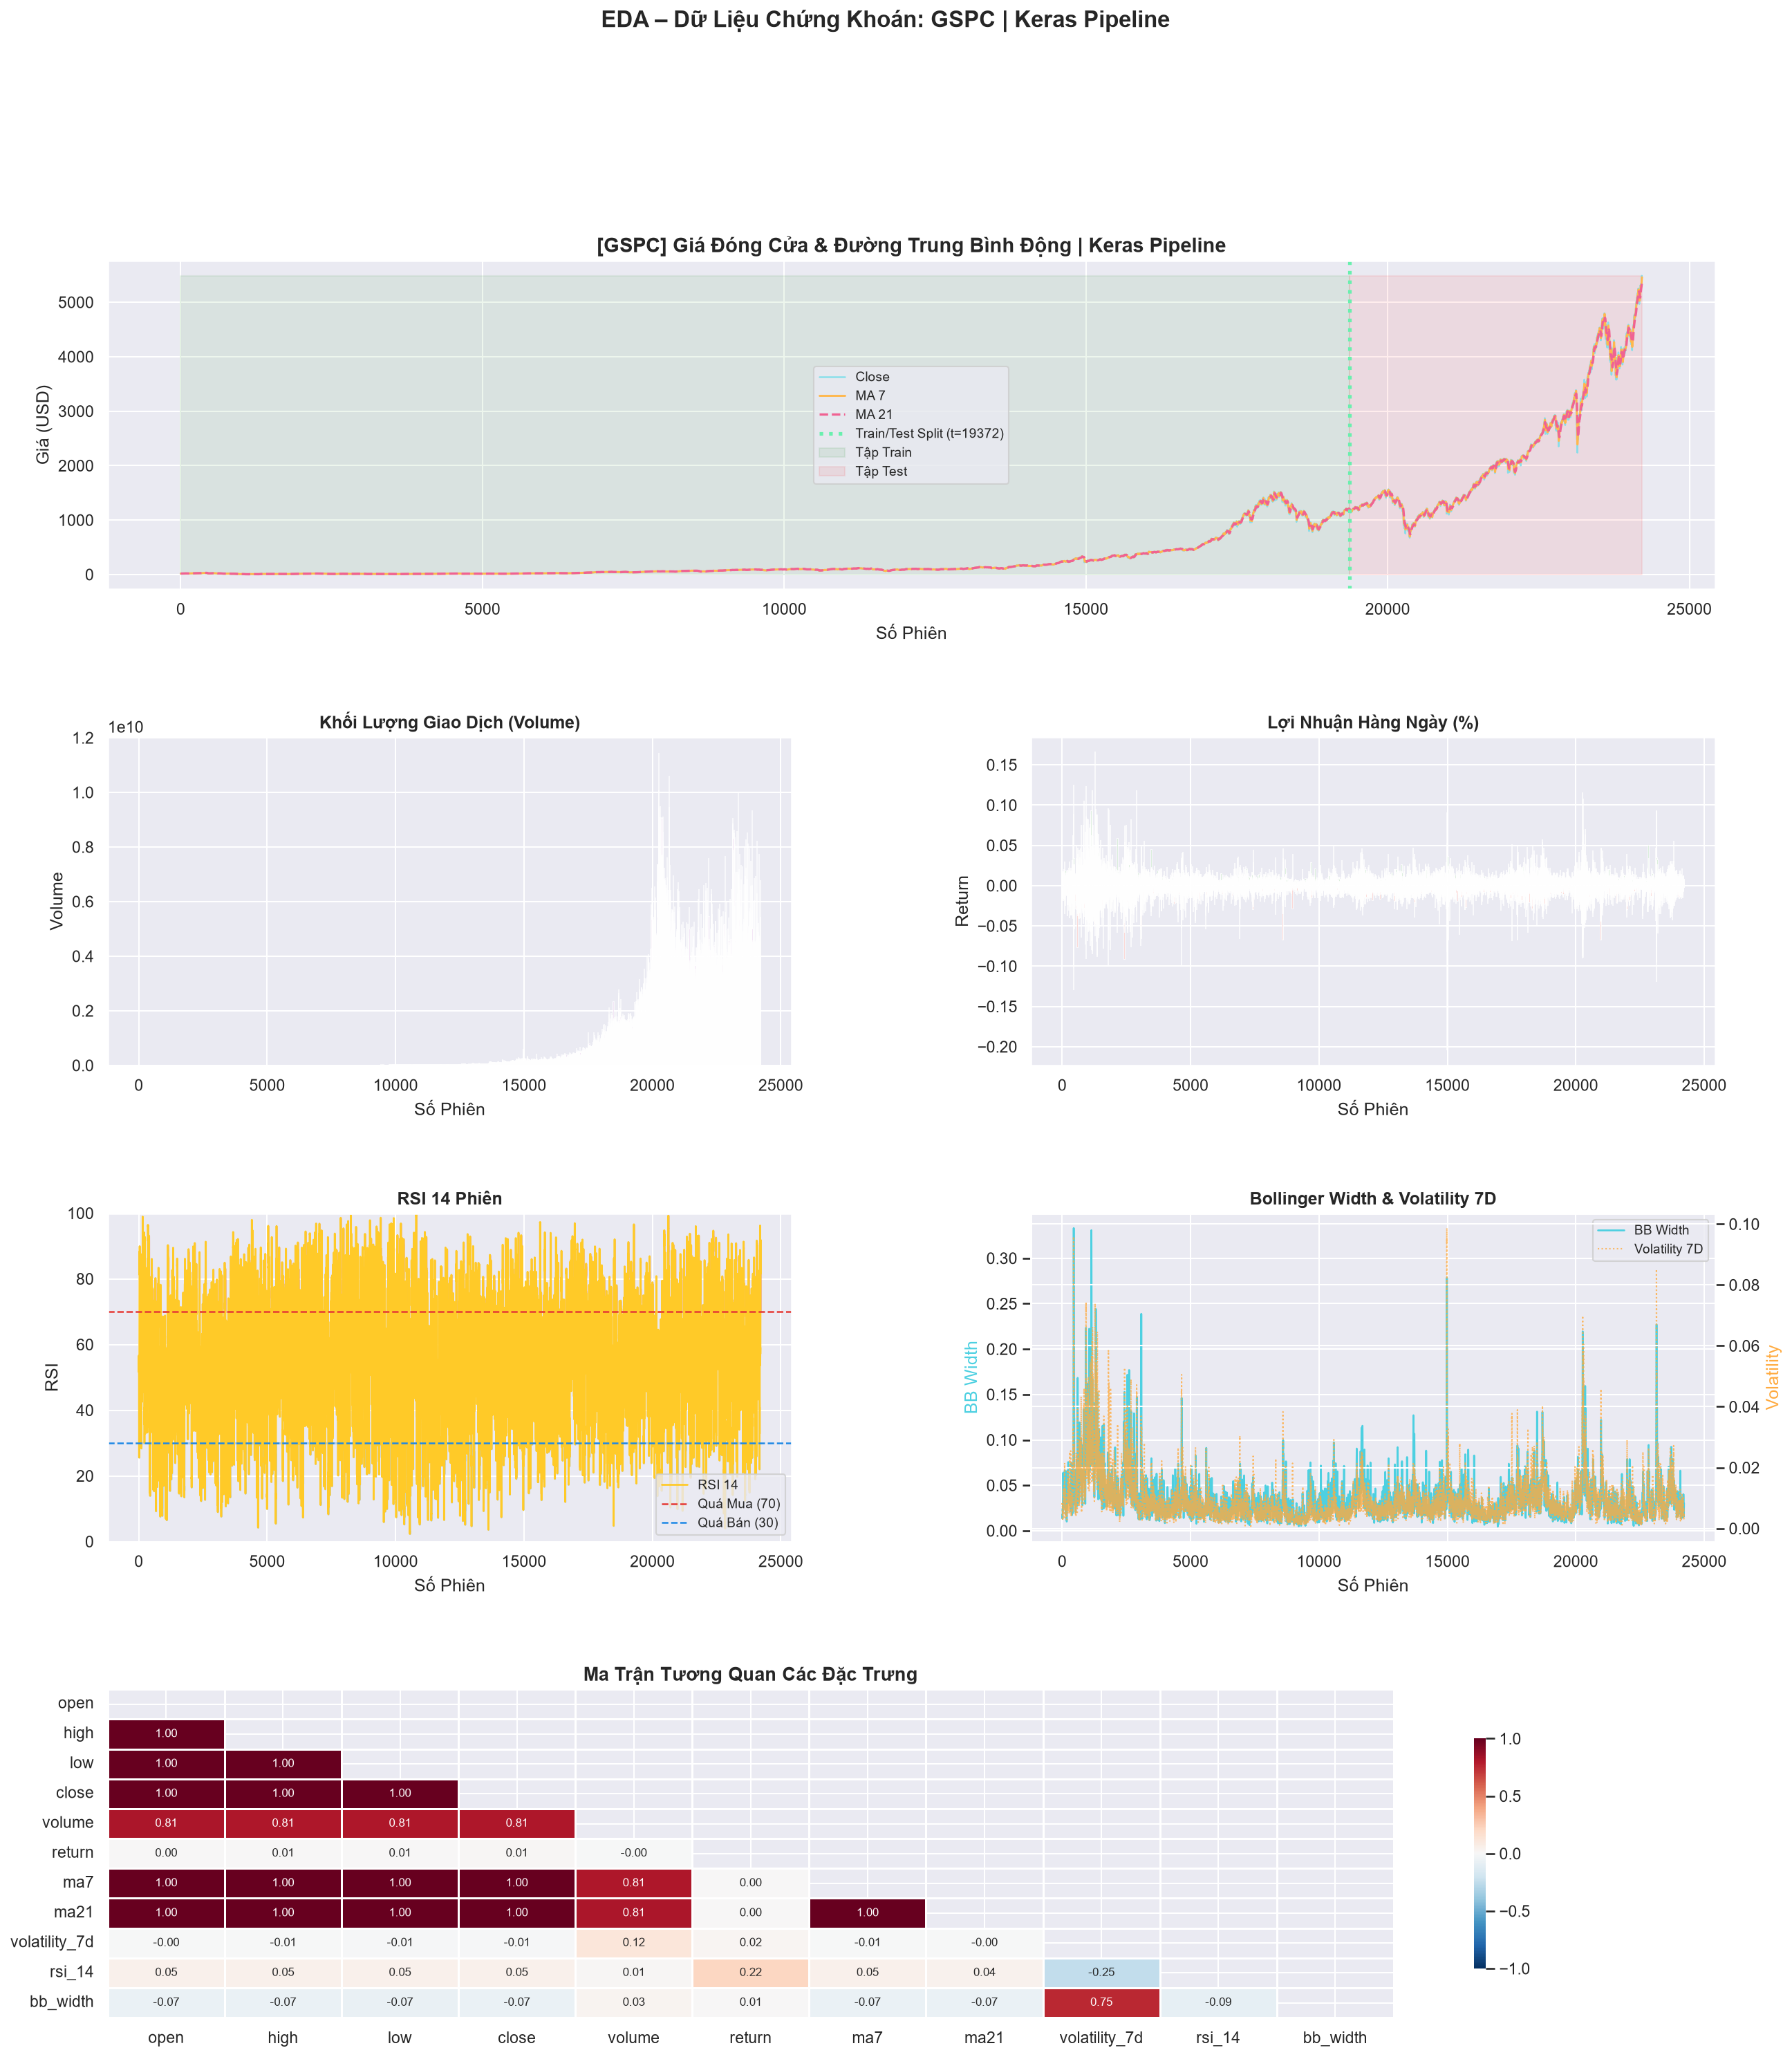

Kết Quả Huấn Luyện Keras SimpleRNN:


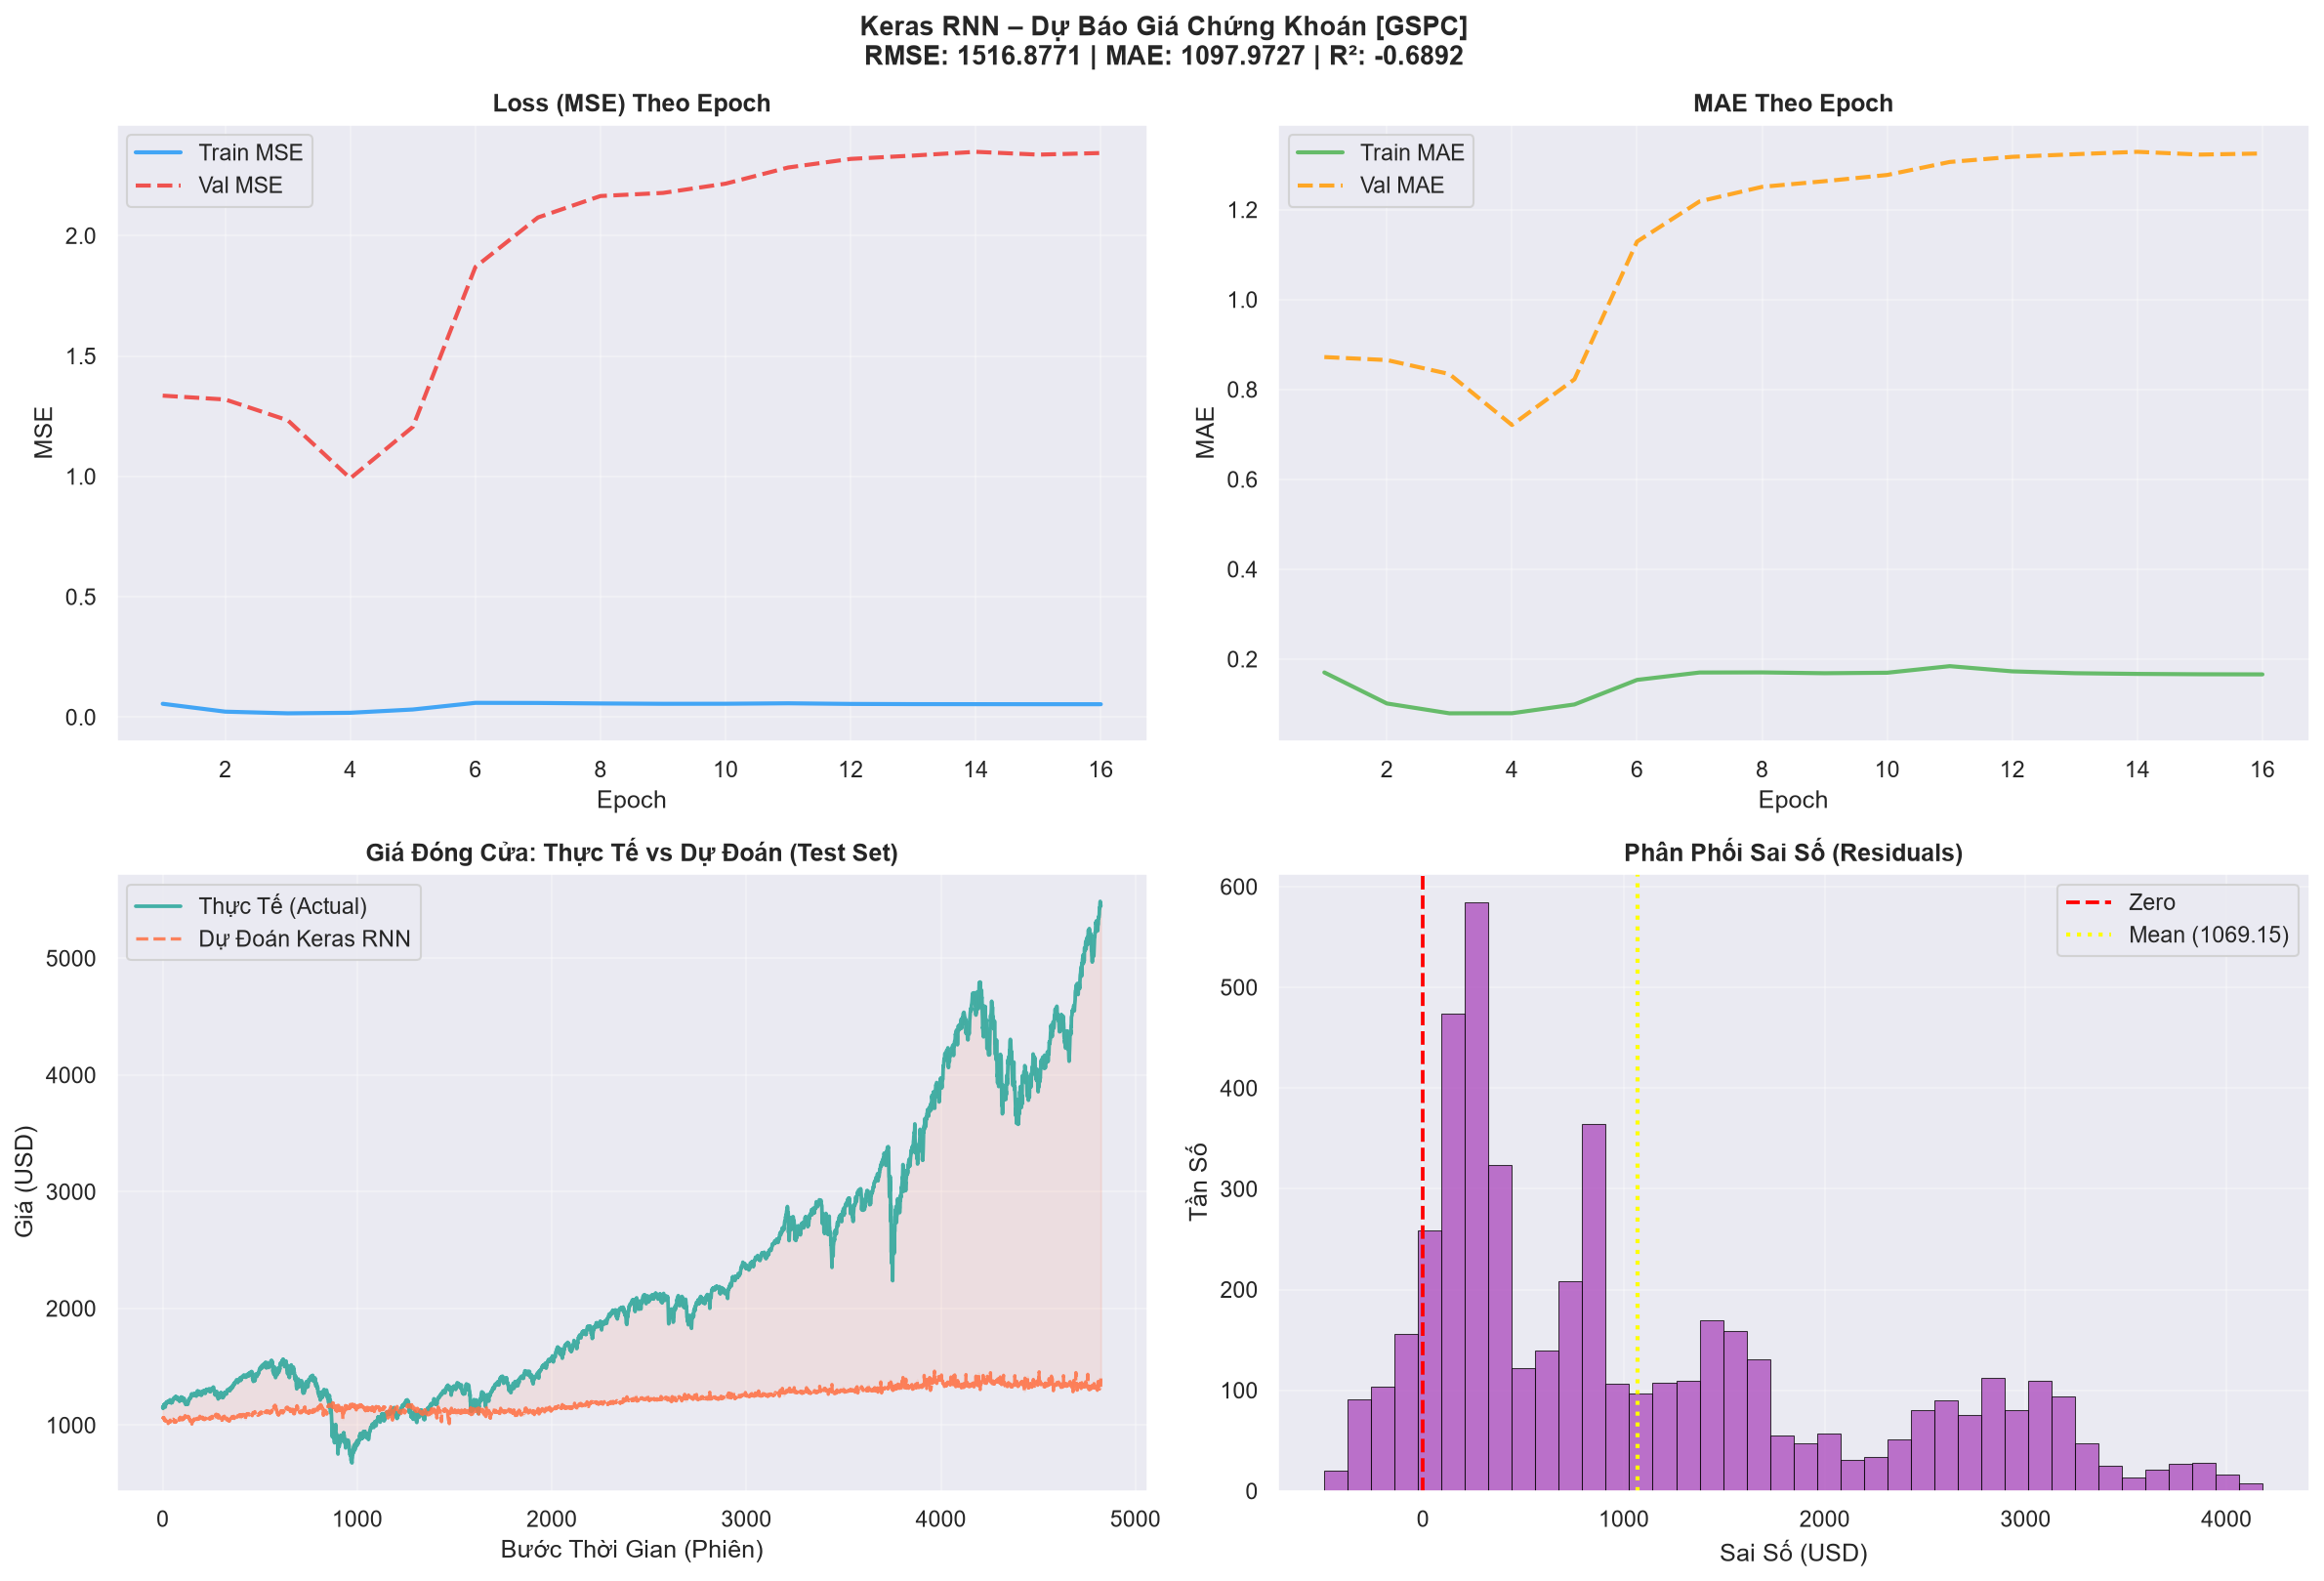

In [13]:
# ── Hiển thị biểu đồ Keras SimpleRNN ──
eda_k_path = os.path.join(FIG_DIR, f'eda_{TL}_keras.png')
if os.path.exists(eda_k_path):
    print('EDA – Chứng khoán (Keras):')
    display(Image(filename=eda_k_path, width=950))

rnn_k_path = os.path.join(FIG_DIR, f'stock_{TL}_rnn_keras.png')
if os.path.exists(rnn_k_path):
    print('Kết Quả Huấn Luyện Keras SimpleRNN:')
    display(Image(filename=rnn_k_path, width=950))

---
## Phần 4: So Sánh Framework PyTorch vs Keras (Vanilla RNN)

Đối Đầu Framework: PyTorch RNN vs Keras RNN:


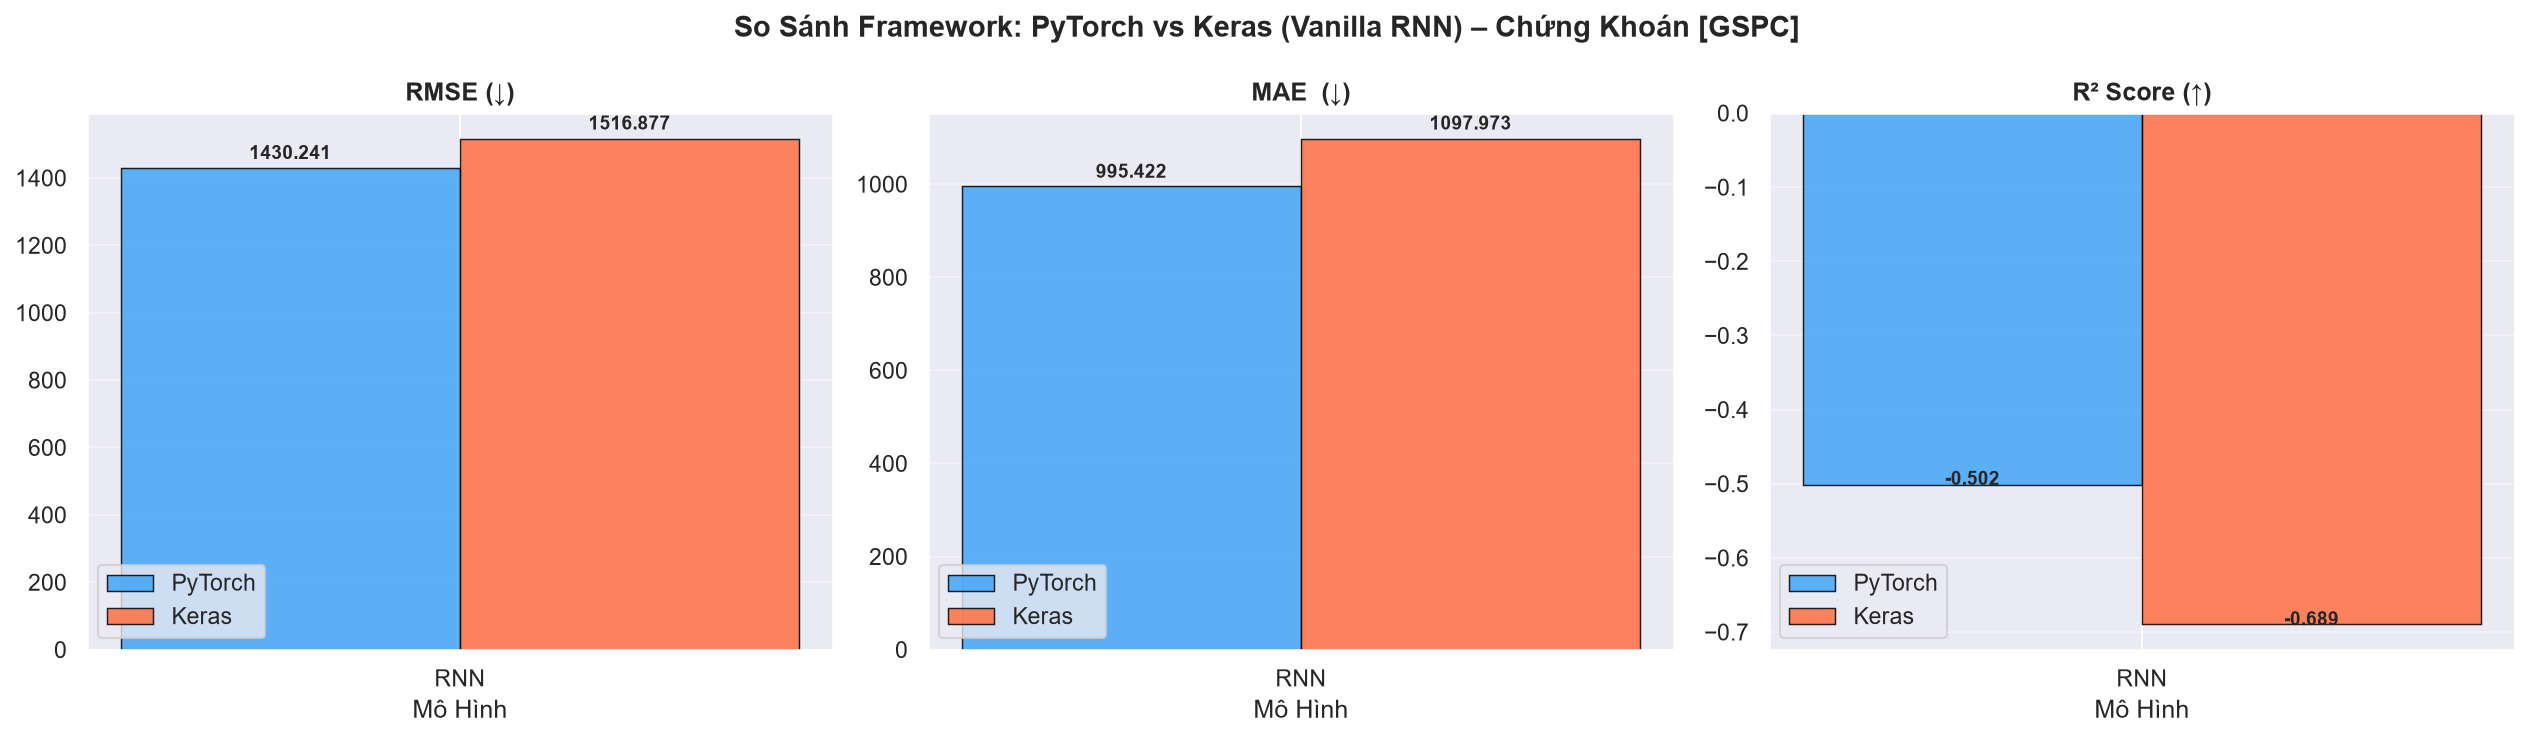

In [14]:
# ── Biểu đồ so sánh đối đầu PyTorch RNN vs Keras RNN ──
fw_path = os.path.join(FIG_DIR, f'stock_framework_{TL}.png')
if os.path.exists(fw_path):
    print('Đối Đầu Framework: PyTorch RNN vs Keras RNN:')
    display(Image(filename=fw_path, width=950))

In [15]:
# ── Bảng tổng hợp số liệu ──
print('=' * 62)
print(f'  BẢNG TỔNG HỢP HIỆU NĂNG VANILLA RNN – [{TICKER}] S&P 500')
print('=' * 62)
print(f'  {"Framework":<12} {"Model":<12} {"RMSE":>10} {"MAE":>10} {"R²":>10}')
print('  ' + '─' * 52)
for m, r in pytorch_results.items():
    print(f'  {"PyTorch":<12} {m:<12} {r["rmse"]:>10.4f} {r["mae"]:>10.4f} {r["r2"]:>10.4f}')
for m, r in keras_results.items():
    print(f'  {"Keras":<12} {m:<12} {r["rmse"]:>10.4f} {r["mae"]:>10.4f} {r["r2"]:>10.4f}')
print('=' * 62)

# So sánh framework nào tối ưu hơn
pt_rmse = pytorch_results['RNN']['rmse']
ks_rmse = keras_results['RNN']['rmse']
best_fw = 'PyTorch' if pt_rmse < ks_rmse else 'Keras'
diff = abs(pt_rmse - ks_rmse)
print(f'  Framework đạt RMSE thấp hơn: {best_fw} (chênh lệch: {diff:.4f})')

  BẢNG TỔNG HỢP HIỆU NĂNG VANILLA RNN – [^GSPC] S&P 500
  Framework    Model              RMSE        MAE         R²
  ────────────────────────────────────────────────────
  PyTorch      RNN           1430.2414   995.4224    -0.5018
  Keras        RNN           1516.8771  1097.9727    -0.6892
  Framework đạt RMSE thấp hơn: PyTorch (chênh lệch: 86.6358)


---
## Phần 5: Thử Nghiệm Ticker Khác (Tuỳ Chọn)

In [16]:
# ── Thử nghiệm với chỉ số khác (bỏ comment để chạy) ──
other_ticker = '^DJI'   # Dow Jones Industrial Average
pt_res2 = pt.run_pipeline(ticker=other_ticker, window_size=20, epochs=50, hidden_dim=128)
ks_res2 = ks.run_pipeline(ticker=other_ticker, window_size=20, epochs=60, units=128, pytorch_results=pt_res2)

print(' Bỏ comment đoạn code trên để chạy dự báo với các ticker quốc tế khác.')
print(f'   Gợi ý: {tickers[:8]}')


  PYTORCH STOCK PIPELINE (RNN) – DJI
[Stock] Ticker: ^DJI | Tổng: 8,159 phiên | Train: 6,507 | Test: 1,612 | Features: 11 | Window: 20

[EDA] Đang vẽ biểu đồ phân tích...
[OK] EDA → G:\Workplace\ISD-Assignment06\notebooks\..\src\..\reports\figures\eda_DJI_pytorch.png

  [Train] RNN (Vanilla RNN)...
  [010/50] Train: 0.117140 | Val: 0.333599
  [020/50] Train: 0.046664 | Val: 0.915984
  [030/50] Train: 0.045640 | Val: 0.927595
  [040/50] Train: 0.045342 | Val: 0.929469
  [050/50] Train: 0.045181 | Val: 0.930504
  → RMSE: 7439.5701 | MAE: 6080.6973 | R²: -1.5976
[OK] RNN → G:\Workplace\ISD-Assignment06\notebooks\..\src\..\reports\figures\stock_DJI_rnn_pytorch.png

───────────────────────────────────────────────────────
  KẾT QUẢ PYTORCH (RNN) – Chứng Khoán [DJI]
───────────────────────────────────────────────────────
  Model          RMSE        MAE         R²
  ──────────────────────────────────────────
  RNN       7439.5701  6080.6973    -1.5976

  KERAS STOCK PIPELINE (RNN) – DJI
[Sto

Model: "RNN_stock"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ RNN_1 (SimpleRNN)                    │ (None, 20, 128)             │          17,920 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 20, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 20, 128)             │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ RNN_2 (SimpleRNN)                    │ (None, 64)                  │          12,352 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 64)                  │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output (Dense)                       │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 37,313 (145.75 KB)

 Trainable params: 36,929 (144.25 KB)

 Non-trainable params: 384 (1.50 KB)


Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 13: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
Epoch 13: early stopping
Restoring model weights from the end of the best epoch: 1.
  → RMSE: 15091.6326 | MAE: 14245.7285 | R²: -9.6891
[OK] RNN → G:\Workplace\ISD-Assignment06\notebooks\..\src\..\reports\figures\stock_DJI_rnn_keras.png
[OK] Framework comparison → G:\Workplace\ISD-Assignment06\notebooks\..\src\..\reports\figures\stock_framework_DJI.png

───────────────────────────────────────────────────────
  KẾT QUẢ KERAS (RNN) – Chứng Khoán [DJI]
───────────────────────────────────────────────────────
  Model          RMSE        MAE         R²
  ──────────────────────────────────────────
  RNN      15091.6326 14245.7285    -9.6891
 Bỏ comment đoạn code trên để chạy dự báo với các ticker quốc tế khác.
   Gợi ý: ['000001.SS', '399001.SZ', 'IMOEX.ME', '^AORD', '^AXJO', '^BFX', '^BSESN', '^BUK100P']


---
## Phần 6: Nhận Xét & Đánh Giá Chuyên Sâu Về Vanilla RNN

### 6.1. Đặc Thù Của Chuỗi Thời Gian Chứng Khoán
- **Non-Stationarity (Bất định thời gian):** Phân phối của giá thay đổi liên tục, có xu hướng bùng nổ theo năm (bull run) và điều chỉnh sâu (bear market).
- **Hiện tượng Random Walk:** Giá phiên ngày mai $P_t$ thường tương quan cực mạnh với giá phiên hôm nay $P_{t-1}$. Vì vậy mô hình hồi quy thường dễ rơi vào xu hướng "dự báo trễ 1 nhịp" (lagged persistence).
- **Bộ 11 chỉ báo kỹ thuật:** Giúp cung cấp cho RNN thông tin về đà tăng/giảm (RSI), độ biến động rủi ro (Bollinger Width, Volatility 7D) và xu hướng trung hạn (MA7, MA21).

### 6.2. Cơ Chế Hoạt Động & Thách Thức Toán Học Của Vanilla RNN
1. **Cập nhật trạng thái ẩn (Hidden State Transition):**
   $$h_t = \tanh(W_{xh} x_t + W_{hh} h_{t-1} + b_h)$$
   $$y_t = W_{hy} h_t + b_y$$
   Vanilla RNN dùng chung một ma trận hồi quy $W_{hh}$ cho mọi bước thời gian $t \in [1, 20]$.

2. **Hiện tượng Triệt tiêu Gradient (Vanishing Gradient) trong BPTT:**
   Khi tính đạo hàm ngược qua 20 bước thời gian:
   $$\frac{\partial L}{\partial h_1} = \frac{\partial L}{\partial h_T} \prod_{t=2}^T \left[\text{diag}(1-h_t^2) \cdot W_{hh}^T\right]$$
   - Do hàm $\tanh$ có đạo hàm $1 - h_t^2 \in (0, 1]$ và giá trị riêng của $W_{hh}$ thường nhỏ hơn 1 khi mô hình ổn định, tích liên tiếp qua 20 bước làm gradient tiệm cận 0.
   - **Hệ quả thực tế:** Vanilla RNN ghi nhớ rất rõ các biến động của 3–5 phiên gần nhất (recency effect), nhưng gặp khó khăn khi liên kết các nhịp sóng dài hơn 15 phiên.

### 6.3. So Sánh Thực Thi Giữa PyTorch và Keras
- **PyTorch (`nn.RNN`):** Cho phép can thiệp trực tiếp vào vòng lặp training, áp dụng `clip_grad_norm_` ở mức gradient tensor giúp chống bùng nổ gradient một cách triệt để.
- **Keras (`SimpleRNN`):** Kết hợp chặt chẽ với tầng `BatchNormalization` giúp chuẩn hóa các vector kích hoạt giữa các tầng RNN, giúp loss giảm đều đặn hơn và tránh hiện tượng bão hòa hàm kích hoạt $\tanh$.

### 6.4. Các Giải Pháp Đã Áp Dụng Để Tối Ưu Vanilla RNN
1. **Chuẩn hóa MinMaxScaler/RobustScaler:** Đưa dữ liệu về miền $[0, 1]$ để các hàm phi tuyến $\tanh$ không bị bão hòa ngay từ bước đầu.
2. **Gradient Clipping:** Cắt ngưỡng gradient norm ở mức 1.0 ngăn chặn trọng số bị phá hủy do các cú sốc giá.
3. **Sliding Window:** Giới hạn cửa sổ trượt $T=20$ phiên là điểm cân bằng tối ưu giữa việc cung cấp đủ ngữ cảnh tháng và giảm thiểu vanishing gradient.
4. **Dropout & ReduceLROnPlateau:** Giảm learning rate khi validation loss đi ngang giúp Vanilla RNN tìm được cực tiểu địa phương tốt hơn.
